# Day 26 — Do the moving averages look right?

**Acceptance:** a chart of one ticker's price with its three moving averages looks visually correct.

"Visually correct" is a few concrete things, each checked below before the chart is drawn:

1. the averages are the numbers they claim to be (a 20-session SMA by hand, from the raw store);
2. they **lag** the price: the 200-session line is the smoothest and the slowest to turn;
3. they **hug** the price: no level jump, no offset (a split must not show up as a cliff);
4. a golden or death cross is flagged on the bar where the 50 and 200 lines actually meet.

The ticker is **AAPL**, in its listing currency (`price="adj_close"`), so the chart reads
like any broker's. The store ends 2026-10-14, so that is the pinned date.

In [1]:
import math

import matplotlib.pyplot as plt
import pandas as pd

from finmgr.data.benchmarks import read_total_return
from finmgr.features.trend import read_trend

TICKER = "AAPL"
AS_OF = "2026-10-14"
START = "2023-10-01"
t = pd.Timestamp(AS_OF).date()

trend = read_trend(TICKER, as_of=AS_OF, price="adj_close").set_index("date")
print(len(trend), "bars,", trend.index.min(), "to", trend.index.max())

4221 bars, 2010-01-04 to 2026-10-14


## Check 1 — the 20, 50 and 200-session SMAs by hand

In [2]:
bars = read_total_return(TICKER, as_of=AS_OF).sort_values("date").reset_index(drop=True)
i = bars.index[bars["date"] == t][0]
for w in (20, 50, 200):
    hand = float(bars["adj_close"].iloc[i - w + 1 : i + 1].mean())
    mod = float(trend.loc[t, f"sma_{w}"])
    print(f"sma_{w}: hand {hand:.6f}   module {mod:.6f}")
    assert math.isclose(hand, mod, rel_tol=1e-12)
# The EMA's seed is long forgotten: the 20-session EMA by hand over the last 400 bars.
p = bars["adj_close"].iloc[: i + 1].to_numpy()
alpha, e = 2 / 21, p[-400:-380].mean()
for x in p[-380:]:
    e = alpha * x + (1 - alpha) * e
print(f"ema_20: hand {e:.6f}   module {trend.loc[t, 'ema_20']:.6f}")
assert math.isclose(e, trend.loc[t, "ema_20"], rel_tol=1e-6)
print("MATCH")

sma_20: hand 336.807503   module 336.807503
sma_50: hand 324.442256   module 324.442256
sma_200: hand 291.441593   module 291.441593
ema_20: hand 335.496237   module 335.496237
MATCH


## Check 2 — lag and smoothness

The longer the window, the less the line wiggles and the further its turning points trail the price's.

In [3]:
view = trend.loc[pd.Timestamp(START).date() :]
wiggle = {c: view[c].diff().abs().sum() for c in ["adj_close", "sma_20", "sma_50", "sma_200"]}
print({k: round(v, 1) for k, v in wiggle.items()})
assert wiggle["adj_close"] > wiggle["sma_20"] > wiggle["sma_50"] > wiggle["sma_200"]
for kind in ("sma", "ema"):
    w = {n: view[f"{kind}_{n}"].diff().abs().sum() for n in (20, 50, 200)}
    assert w[20] > w[50] > w[200]
print("smoother with every window")

{'adj_close': np.float64(2022.6), 'sma_20': np.float64(502.8), 'sma_50': np.float64(302.6), 'sma_200': np.float64(149.6)}
smoother with every window


## Check 3 — the lines hug the price

Over the plotted span the 20-session SMA should stay within a few percent of the price, and no day-to-day move in any average should look like a jump.

In [4]:
print(view[["dist_sma_20", "dist_sma_50", "dist_sma_200"]].describe().round(3))
assert view["dist_sma_20"].abs().max() < 0.25
assert view["dist_sma_20"].abs().median() < 0.04
for w in (20, 50, 200):
    assert view[f"sma_{w}"].pct_change().abs().max() < 0.03, w
print("no offsets, no jumps")

       dist_sma_20  dist_sma_50  dist_sma_200
count      762.000      762.000       762.000
mean         0.009        0.021         0.078
std          0.038        0.058         0.096
min         -0.186       -0.240        -0.245
25%         -0.018       -0.017         0.022
50%          0.010        0.021         0.092
75%          0.036        0.063         0.156
max          0.100        0.176         0.261
no offsets, no jumps


## Check 4 — crosses happen where the lines meet

In [5]:
events = view[(view["golden_cross"] == 1) | (view["death_cross"] == 1)]
print(events[["sma_50", "sma_200", "golden_cross", "death_cross"]].round(2))
full = trend["sma_50"] - trend["sma_200"]
for day, row in events.iterrows():
    k = trend.index.get_loc(day)
    before, now = full.iloc[k - 1], full.iloc[k]
    assert (now > 0 and before <= 0) if row["golden_cross"] == 1 else (now <= 0 and before > 0)
    assert abs(now) / row["sma_200"] < 0.01  # they meet, near enough
print(len(events), "crosses, each on the bar the 50 and 200 lines change sides")

            sma_50  sma_200  golden_cross  death_cross
date                                                  
2024-03-14  181.42   181.47           0.0          1.0
2024-06-13  180.64   180.16           1.0          0.0
2025-04-07  226.75   227.08           0.0          1.0
2025-09-15  220.65   220.29           1.0          0.0
4 crosses, each on the bar the 50 and 200 lines change sides


## The chart

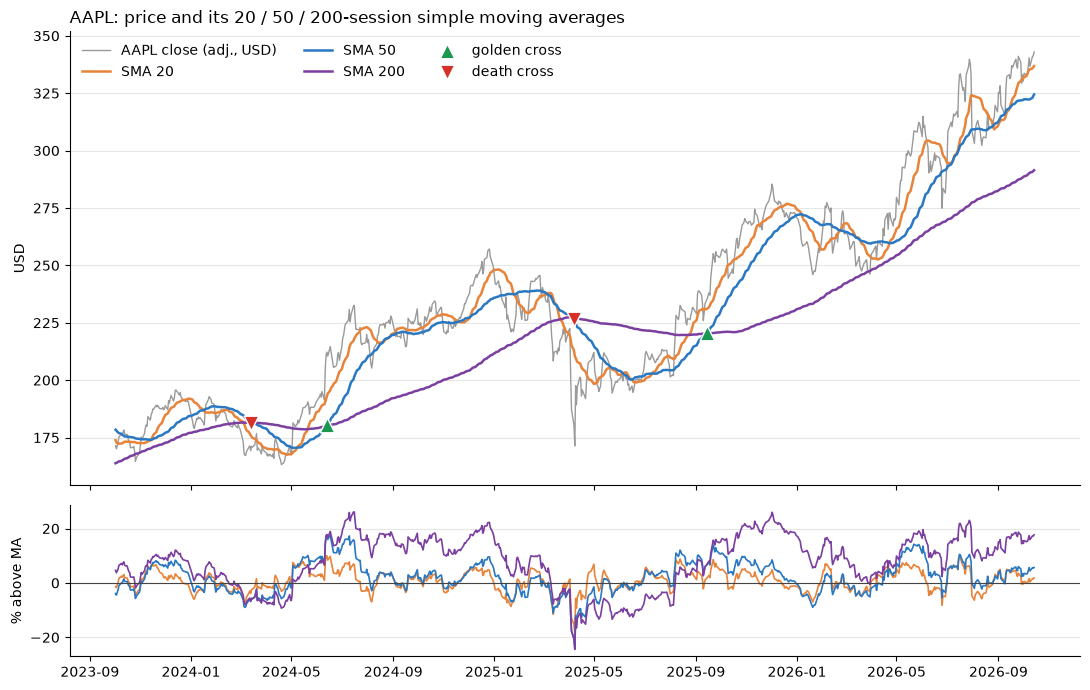

In [6]:
COLORS = {"sma_20": "#e8833a", "sma_50": "#2a78c2", "sma_200": "#7b3fa0"}
fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
)
dates = pd.to_datetime(view.index)
top.plot(dates, view["adj_close"], color="#9a9a9a", lw=1.0, label="AAPL close (adj., USD)")
for col, color in COLORS.items():
    top.plot(dates, view[col], color=color, lw=1.8, label=col.replace("_", " ").upper())
for col, marker, color, name in [
    ("golden_cross", "^", "#1a9850", "golden cross"),
    ("death_cross", "v", "#d73027", "death cross"),
]:
    hit = view[view[col] == 1]
    top.scatter(
        pd.to_datetime(hit.index),
        hit["sma_50"],
        marker=marker,
        s=110,
        color=color,
        edgecolor="white",
        zorder=5,
        label=name,
    )
top.set_title(f"{TICKER}: price and its 20 / 50 / 200-session simple moving averages", loc="left")
top.set_ylabel("USD")
top.legend(loc="upper left", frameon=False, ncol=3)
for col, color in COLORS.items():
    bottom.plot(dates, 100 * view[col.replace("sma", "dist_sma")], color=color, lw=1.2)
bottom.axhline(0, color="#444", lw=0.8)
bottom.set_ylabel("% above MA")
for ax in (top, bottom):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e6e6e6", lw=0.8)
fig.tight_layout()
fig.savefig("docs/day26_trend_AAPL.png", dpi=110)
plt.show()

Read it: the orange 20-session line follows every swing a few days late, the blue 50
cuts through the larger swings, and the purple 200 barely bends: it flattens through the
spring-2025 sell-off and only turns up again once the price has spent months above it. Each
cross marker sits where blue meets purple: death crosses in March 2024 and April 2025, golden
crosses in June 2024 and September 2025. The thin overlap just before June 2024 is the purple
line drawn over the blue, not a gap; the panel has no NaN on the plotted span. The lower
panel is `dist_sma_*`, the column the model reads: positive while the price is above the line.